In [64]:
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score, precision_score, recall_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree


## **loading csv**

In [65]:
df=pd.read_csv("/content/loan_data.csv")
df.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


## **Finding and droping null and repeated values with outliers**

In [66]:
print("Before dropping null values:\n")
print(df.isnull().sum())
df.dropna(inplace=True)
print("After dropping null values:\n")
print(df.isnull().sum())

Before dropping null values:

Loan_ID                0
Gender                24
Married                3
Dependents            25
Education              0
Self_Employed         55
ApplicantIncome        0
CoapplicantIncome      0
LoanAmount            27
Loan_Amount_Term      20
Credit_History        79
Property_Area          0
Loan_Status          367
dtype: int64
After dropping null values:

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [67]:
print("number of dublicated",df.duplicated().sum())
df.drop_duplicates(inplace=True)
print("number of duplicated after dropping:", df.duplicated().sum())

number of dublicated 0
number of duplicated after dropping: 0


<Axes: xlabel='ApplicantIncome'>

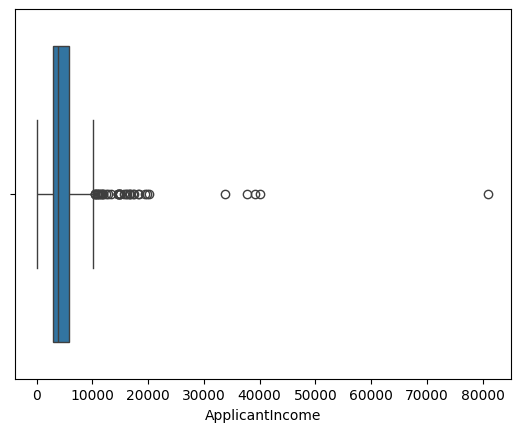

In [68]:
sns.boxplot(x=df["ApplicantIncome"])

<Axes: xlabel='CoapplicantIncome'>

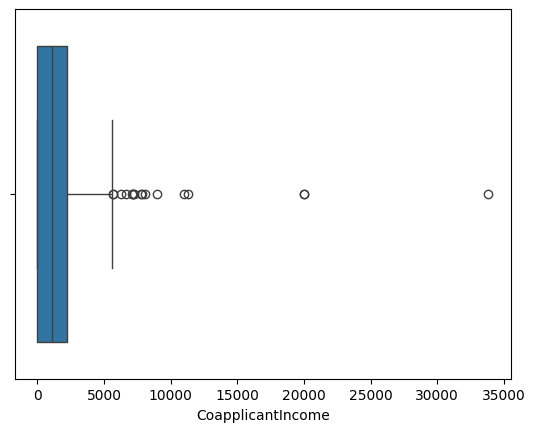

In [69]:
sns.boxplot(x=df["CoapplicantIncome"])

<Axes: xlabel='LoanAmount'>

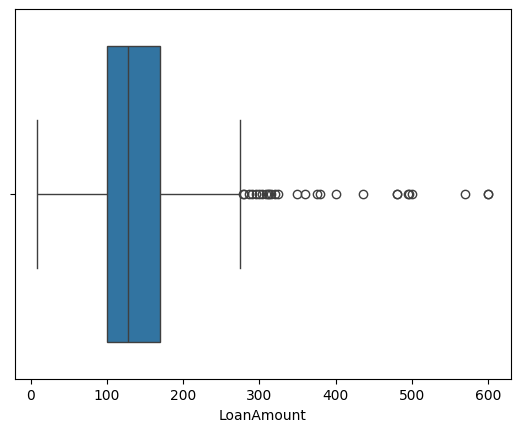

In [70]:
sns.boxplot(x=df["LoanAmount"])

## **Encoding**

In [71]:
#gender
GENDER = LabelEncoder()
df["Gender_encoded"] = GENDER.fit_transform(df["Gender"])
df.head(10)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_encoded
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,1
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,1
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y,1
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N,1
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y,1
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N,1
10,LP001024,Male,Yes,2,Graduate,No,3200,700.0,70.0,360.0,1.0,Urban,Y,1


In [72]:
#married
MARRIED = LabelEncoder()
df["Married_encoded"] = MARRIED.fit_transform(df["Married"])
df.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_encoded,Married_encoded
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1,1
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,1,1
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1,1
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1,0
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,1,1
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y,1,1
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N,1,1
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y,1,1
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N,1,1
10,LP001024,Male,Yes,2,Graduate,No,3200,700.0,70.0,360.0,1.0,Urban,Y,1,1


In [73]:
#depends
DEPENDENTS = LabelEncoder()
df["Dependents_encoded"] = DEPENDENTS.fit_transform(df["Dependents"])
df.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_encoded,Married_encoded,Dependents_encoded
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1,1,1
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,1,1,0
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1,1,0
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1,0,0
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,1,1,2
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y,1,1,0
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N,1,1,3
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y,1,1,2
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N,1,1,1
10,LP001024,Male,Yes,2,Graduate,No,3200,700.0,70.0,360.0,1.0,Urban,Y,1,1,2


In [74]:
#education
EDUCATION = LabelEncoder()
df["Education_encoded"] = EDUCATION.fit_transform(df["Education"])
df.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_encoded,Married_encoded,Dependents_encoded,Education_encoded
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1,1,1,0
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,1,1,0,0
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1,1,0,1
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1,0,0,0
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,1,1,2,0
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y,1,1,0,1
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N,1,1,3,0
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y,1,1,2,0
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N,1,1,1,0
10,LP001024,Male,Yes,2,Graduate,No,3200,700.0,70.0,360.0,1.0,Urban,Y,1,1,2,0


In [75]:
#self
SELF = LabelEncoder()
df["Self_Employed_encoded"] = SELF.fit_transform(df["Self_Employed"])
df.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_encoded,Married_encoded,Dependents_encoded,Education_encoded,Self_Employed_encoded
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1,1,1,0,0
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,1,1,0,0,1
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1,1,0,1,0
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1,0,0,0,0
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,1,1,2,0,1
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y,1,1,0,1,0
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N,1,1,3,0,0
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y,1,1,2,0,0
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N,1,1,1,0,0
10,LP001024,Male,Yes,2,Graduate,No,3200,700.0,70.0,360.0,1.0,Urban,Y,1,1,2,0,0


In [76]:
#property
PROPERTY = LabelEncoder()
df["Property_Area_encoded"] = PROPERTY.fit_transform(df["Property_Area"])
df.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_encoded,Married_encoded,Dependents_encoded,Education_encoded,Self_Employed_encoded,Property_Area_encoded
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1,1,1,0,0,0
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,1,1,0,0,1,2
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1,1,0,1,0,2
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1,0,0,0,0,2
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,1,1,2,0,1,2
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y,1,1,0,1,0,2
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N,1,1,3,0,0,1
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y,1,1,2,0,0,2
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N,1,1,1,0,0,1
10,LP001024,Male,Yes,2,Graduate,No,3200,700.0,70.0,360.0,1.0,Urban,Y,1,1,2,0,0,2


In [77]:
#status
STATUS = LabelEncoder()
df["Loan_Status_encoded"] = STATUS.fit_transform(df["Loan_Status"])
df.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Gender_encoded,Married_encoded,Dependents_encoded,Education_encoded,Self_Employed_encoded,Property_Area_encoded,Loan_Status_encoded
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,1,1,1,0,0,0,0
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,1,1,0,0,1,2,1
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,1,1,0,1,0,2,1
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,1,0,0,0,0,2,1
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,1,1,2,0,1,2,1
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y,1,1,0,1,0,2,1
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N,1,1,3,0,0,1,0
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y,1,1,2,0,0,2,1
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N,1,1,1,0,0,1,0
10,LP001024,Male,Yes,2,Graduate,No,3200,700.0,70.0,360.0,1.0,Urban,Y,1,1,2,0,0,2,1


## **selecting x and y**

In [78]:
X = df[["Gender_encoded","Married_encoded","Dependents_encoded","Education_encoded","Self_Employed_encoded","ApplicantIncome","CoapplicantIncome","LoanAmount",
    "Loan_Amount_Term","Credit_History","Property_Area_encoded"]]
Y = df["Loan_Status_encoded"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (480, 11)
y shape: (480,)


## **splitting of data**

In [79]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.20,random_state=42)
print("records for training:",len(X_train))
print("records for testing:",len(X_test))

records for training: 384
records for testing: 96


## **Scalar**

In [80]:
num_cols = ["ApplicantIncome","CoapplicantIncome","LoanAmount","Loan_Amount_Term"]
my_scaler = StandardScaler()
X_train[num_cols] = my_scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = my_scaler.transform(X_test[num_cols])
print(X_train)

     Gender_encoded  Married_encoded  Dependents_encoded  Education_encoded  \
172               1                1                   3                  1   
288               0                0                   0                  0   
607               1                1                   2                  1   
55                1                1                   2                  0   
461               1                1                   3                  0   
..              ...              ...                 ...                ...   
141               1                0                   0                  0   
350               1                1                   0                  0   
445               1                1                   1                  0   
558               1                1                   0                  0   
137               1                1                   2                  0   

     Self_Employed_encoded  ApplicantIncome  Coappl

## **logistic**

In [81]:
logr = LogisticRegression()
logr.fit(X_train, Y_train)

LogisticRegression()

In [82]:
y_pred = logr.predict(X_test)

comparison = pd.DataFrame({
    'actual_results': Y_test,
    'results_by_model': y_pred
})

comparison.head(10)

,actual_results,results_by_model
92,1,1
529,1,1
505,1,1
358,0,0
512,1,1
220,0,0
347,1,1
482,1,1
97,1,1
566,1,1


In [108]:
print("Accuracy:", accuracy_score(Y_test, y_pred))
print("Precision:", precision_score(Y_test, y_pred))
print("Recall:", recall_score(Y_test, y_pred))
print("F1 Score:", f1_score(Y_test, y_pred))

Accuracy: 0.8229166666666666
Precision: 0.8
Recall: 1.0
F1 Score: 0.8888888888888888


In [111]:
cm = confusion_matrix(Y_test, y_pred)
print(cm)

[[11 17]
 [ 0 68]]


## **Decision tree**

In [118]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, Y_train)

DecisionTreeClassifier(random_state=42)

In [119]:
y_pred = tree.predict(X_test)

comparison = pd.DataFrame({
    'actual_results': Y_test,
    'results_by_model': y_pred
})

comparison.head(10)

,actual_results,results_by_model
92,1,1
529,1,1
505,1,1
358,0,0
512,1,1
220,0,0
347,1,1
482,1,1
97,1,1
566,1,1


In [120]:
print("Accuracy:", accuracy_score(Y_test, y_pred))
print("Precision:", precision_score(Y_test, y_pred))
print("Recall:", recall_score(Y_test, y_pred))
print("F1 Score:", f1_score(Y_test, y_pred))

Accuracy: 0.7708333333333334
Precision: 0.8194444444444444
Recall: 0.8676470588235294
F1 Score: 0.8428571428571429


In [121]:
cm = confusion_matrix(Y_test, y_pred)
print(cm)

[[15 13]
 [ 9 59]]


<function matplotlib.pyplot.show(close=None, block=None)>

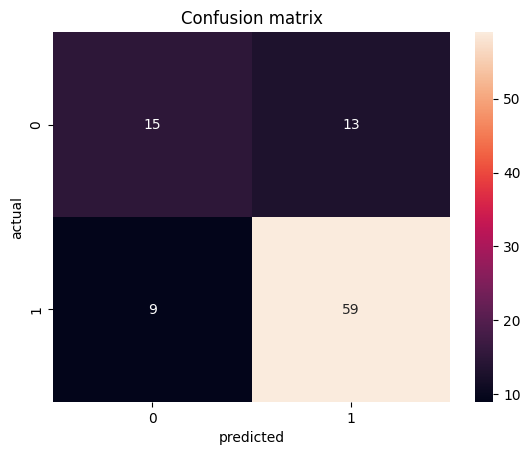

In [123]:
cm = confusion_matrix(Y_test,y_pred)
sns.heatmap(cm , annot=True)
plt.xlabel("predicted")
plt.ylabel("actual")
plt.title("Confusion matrix")
plt.show

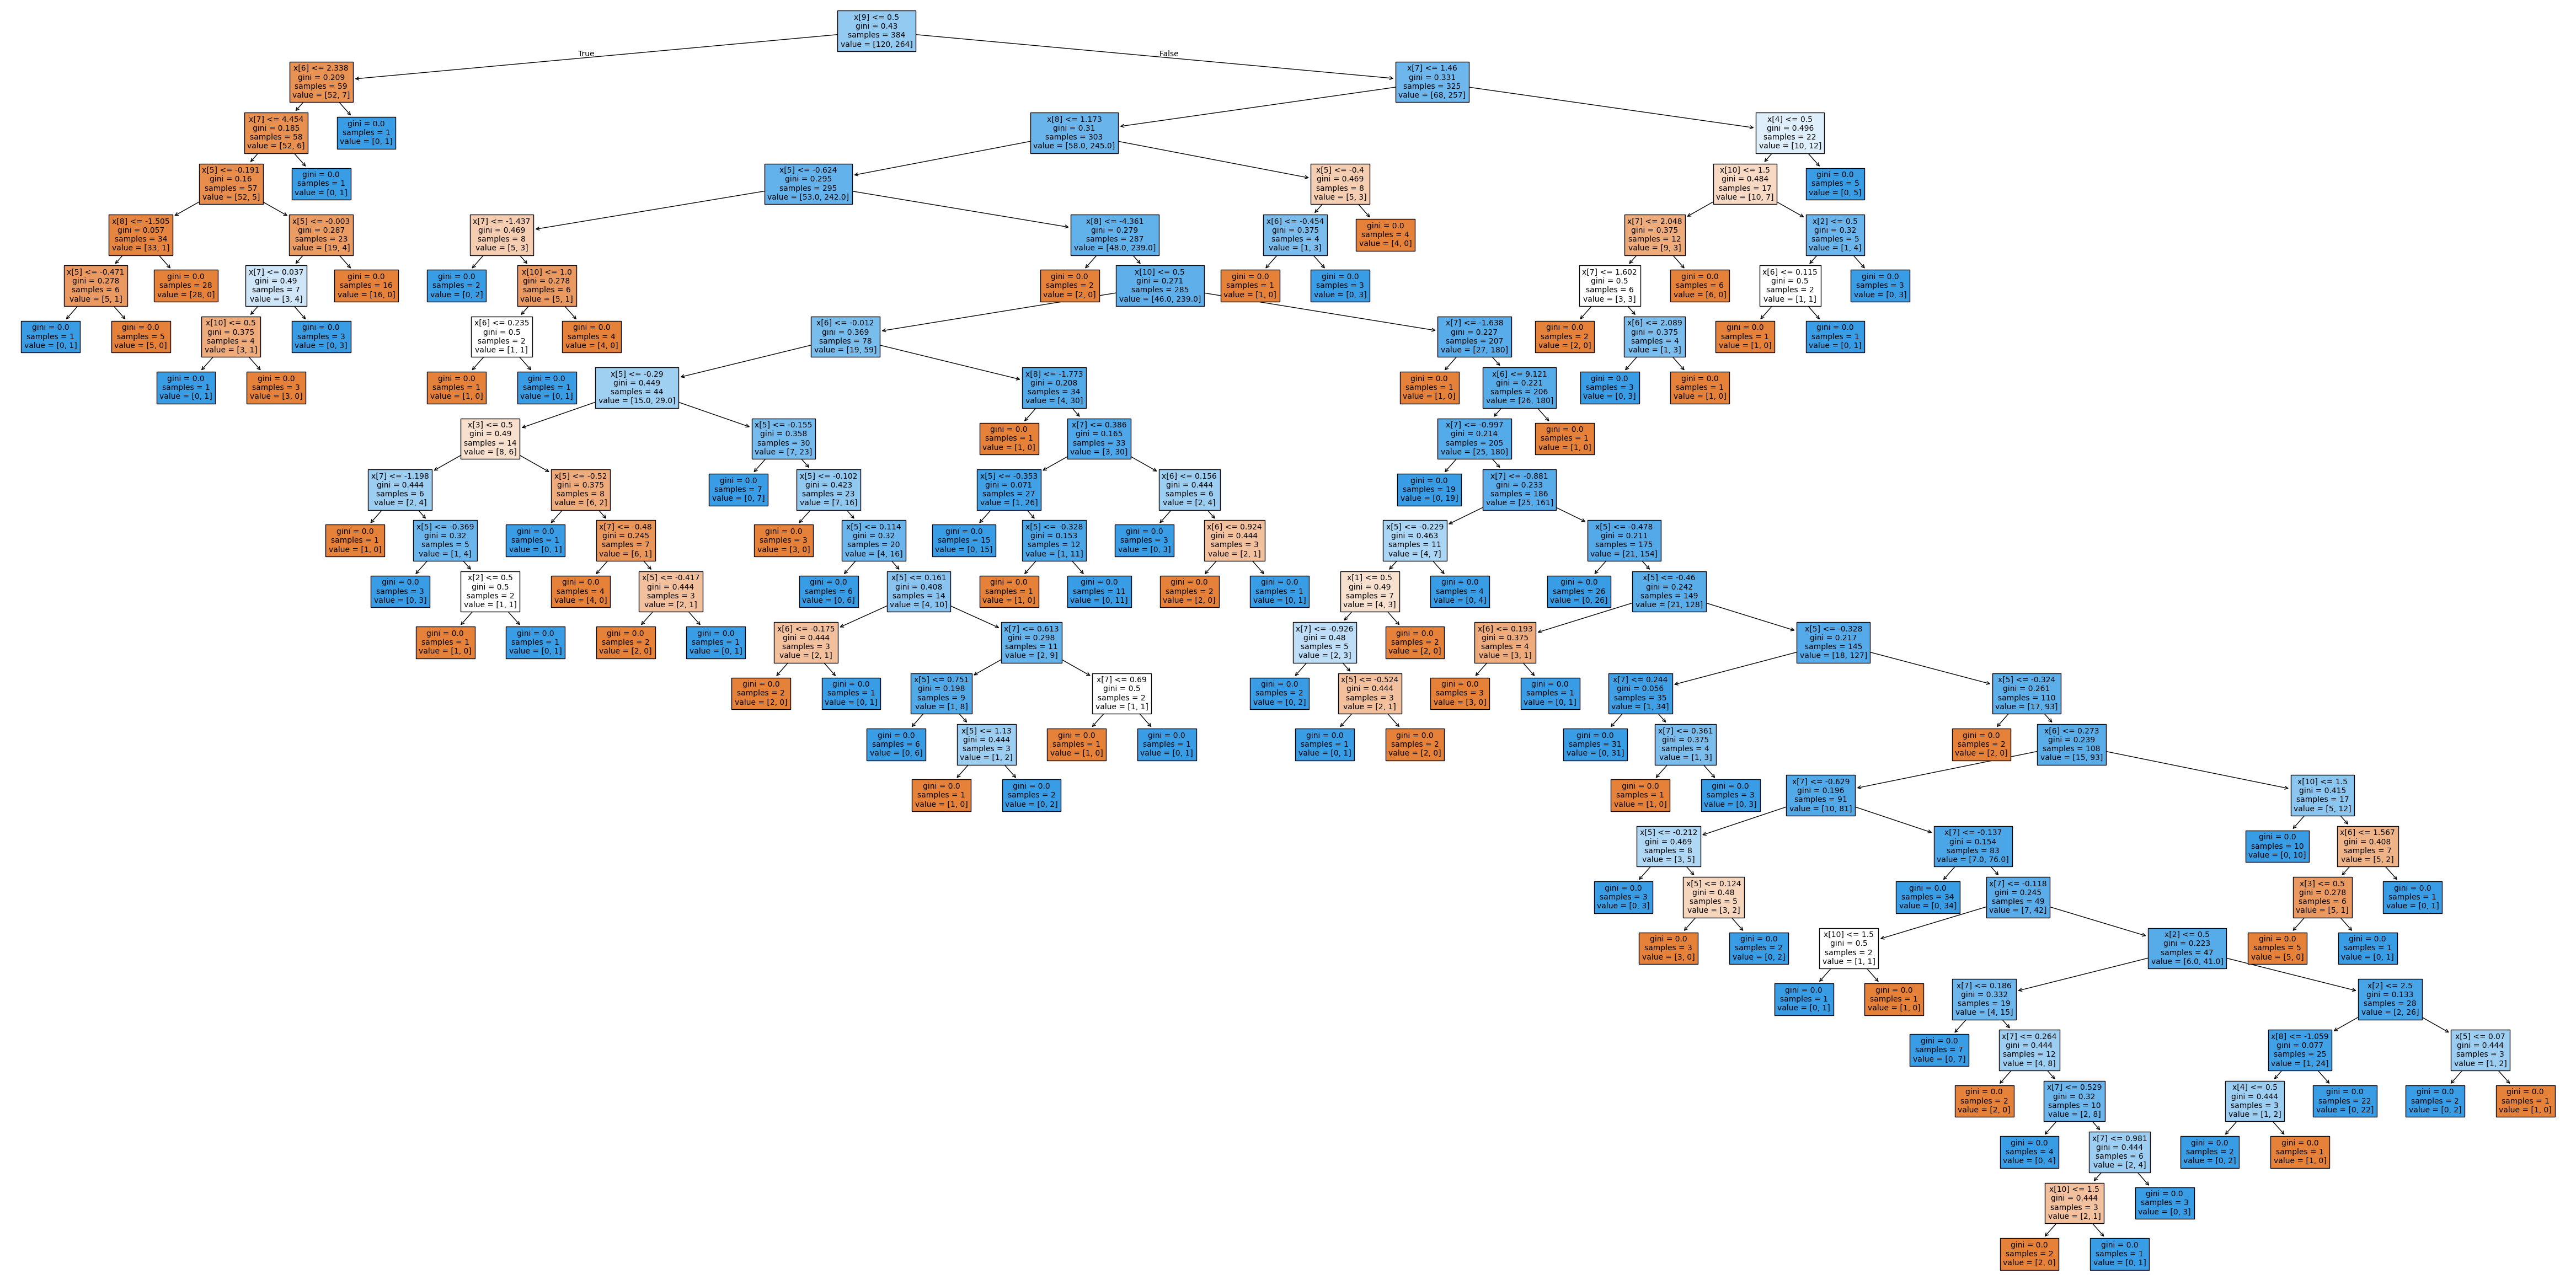

In [124]:
plt.figure(figsize = (60,30))
plot_tree(tree, fontsize =10, filled =True)
plt.savefig("DecisionTree.pdf")

## **Random Forest**

In [126]:
RF = RandomForestClassifier(n_estimators=100,random_state=42)
RF.fit(X_train, Y_train)

RandomForestClassifier(random_state=42)

In [129]:
y_pred = RF.predict(X_test)

comparison = pd.DataFrame({
    'actual_results': Y_test,
    'results_by_model': y_pred
})

comparison.head(10)

,actual_results,results_by_model
92,1,1
529,1,1
505,1,1
358,0,0
512,1,1
220,0,0
347,1,1
482,1,1
97,1,1
566,1,1


In [135]:
print("Accuracy:", accuracy_score(Y_test, y_pred))
print("Precision:", precision_score(Y_test, y_pred, pos_label=1))
print("Recall:", recall_score(Y_test, y_pred, pos_label=1))
print("F1 Score:", f1_score(Y_test, y_pred, pos_label=1))
print("Confusion Matrix:\n", confusion_matrix(Y_test, y_pred))

Accuracy: 0.8229166666666666
Precision: 0.8148148148148148
Recall: 0.9705882352941176
F1 Score: 0.8859060402684564
Confusion Matrix:
 [[13 15]
 [ 2 66]]


<function matplotlib.pyplot.show(close=None, block=None)>

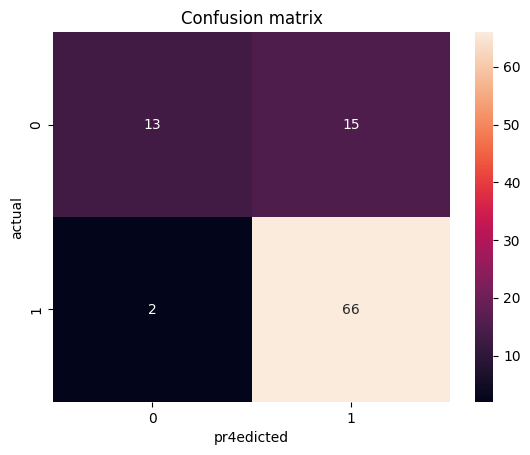

In [137]:
cm = confusion_matrix(Y_test,y_pred)
sns.heatmap(cm , annot=True)
plt.xlabel("pr4edicted")
plt.ylabel("actual")
plt.title("Confusion matrix")
plt.show

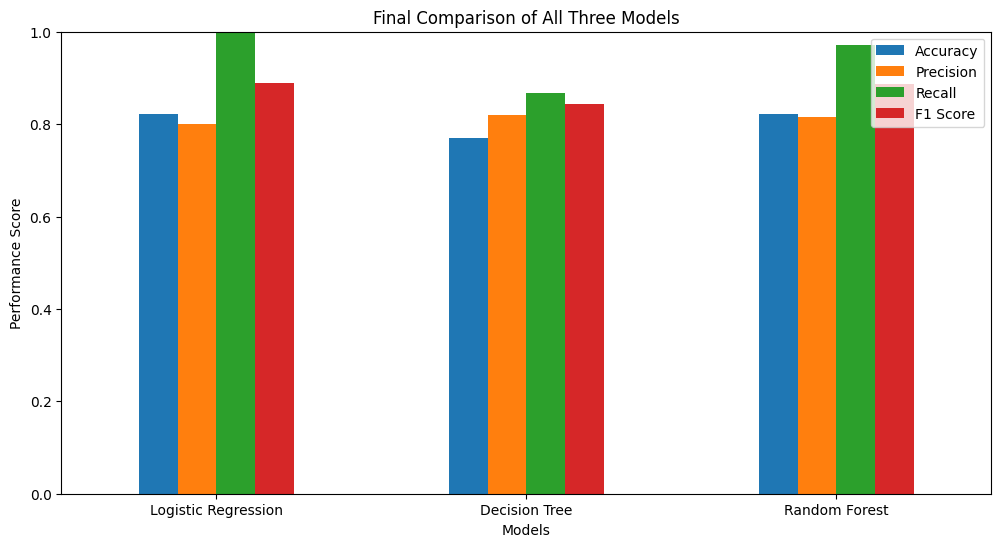

In [140]:
comparison.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Final Comparison of All Three Models")
plt.xlabel("Models")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.show()